# Histograms (cont.), Functions

In [1]:
# datascience
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')


In [2]:
# polars
import polars as pl
from IPython.display import display
import hvplot.polars


## Histogram: Density

In [3]:
# datascience
# Data from https://www.boxofficemojo.com/chart/ww_top_lifetime_gross/
top_movies = Table.read_table('top_movies_2026.csv')
ages = 2026 - top_movies.column('Year')
top_movies = top_movies.with_column('Age', ages)
top_movies


Title,Worldwide Lifetime Gross,Domestic Lifetime Gross,Foreign Lifetime Gross,Year,Age
Avatar,2923710708,785221649,2138489059,2009,17
Avengers: Endgame,2799439100,858373000,1941066100,2019,7
Avatar: The Way of Water,2334484620,688459501,1646025119,2022,4
Titanic,2264812968,674354882,1590458086,1997,29
Ne Zha 2,2259822417,23308176,2236514241,2025,1
Star Wars: Episode VII - The Force Awakens,2071310218,936662225,1134647993,2015,11
Avengers: Infinity War,2052415039,678815482,1373599557,2018,8
Spider-Man: No Way Home,1921426073,814866759,1106559314,2021,5
Zootopia 2,1778775365,410218402,1368556963,2025,1
Inside Out 2,1698863816,652980194,1045883622,2024,2


In [4]:
# polars
# Data from https://www.boxofficemojo.com/chart/ww_top_lifetime_gross/
top_movies_pl = pl.read_csv('top_movies_2026.csv')
ages_pl = 2026 - top_movies_pl.get_column('Year')
top_movies_pl = top_movies_pl.with_columns(pl.Series('Age', ages_pl))
top_movies_pl


Title,Worldwide Lifetime Gross,Domestic Lifetime Gross,Foreign Lifetime Gross,Year,Age
str,i64,i64,i64,i64,i64
"""Avatar""",2923710708,785221649,2138489059,2009,17
"""Avengers: Endgame""",2799439100,858373000,1941066100,2019,7
"""Avatar: The Way of Water""",2334484620,688459501,1646025119,2022,4
"""Titanic""",2264812968,674354882,1590458086,1997,29
"""Ne Zha 2""",2259822417,23308176,2236514241,2025,1
…,…,…,…,…,…
"""Casino Royale""",616585752,167445960,449139792,2006,20
"""The Wandering Earth II""",615023132,5023132,610000000,2023,3
"""Mamma Mia!""",615015484,144330569,470684915,2008,18


In [5]:
# datascience
my_bins = make_array(0, 5, 10, 15, 25, 60)
binned_data = top_movies.bin('Age', bins = my_bins)
binned_data


bin,Age count
0,35
5,45
10,56
15,52
25,12
60,0


In [6]:
# polars
my_bins_pl = pl.Series('values', [0, 5, 10, 15, 25, 60])
binned_data_pl = top_movies_pl.get_column('Age').hist(bins=(my_bins_pl).to_list()).rename({'breakpoint': 'bin', 'count': 'Age count'}).drop('category')
binned_data_pl


bin,Age count
f64,u32
5.0,41
10.0,52
15.0,50
25.0,47
60.0,10


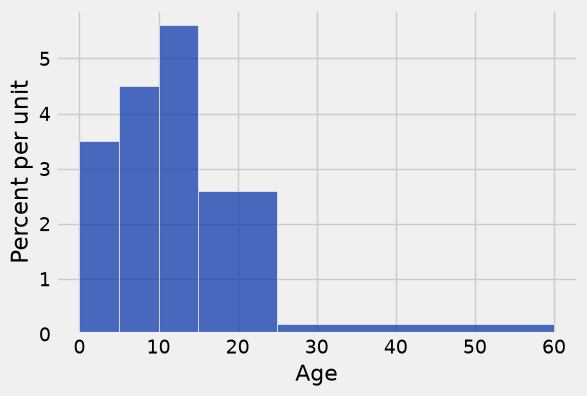

In [7]:
# datascience
# what does normed=True, normed=False do?
top_movies.hist('Age', bins = my_bins, normed=True)


In [8]:
# polars
# hvplot
# what does normed=True, normed=False do?
top_movies_pl.hvplot.hist(y='Age', normed=True, bins=(my_bins_pl).to_list())


:Histogram   [Age]   (Frequency)

### **Discussion Question**: Compare the bins $[0, 5)$ and $[15, 25)$. 

- Which one has more movies?
- Which one is more crowded?

---

### Flat Tops and the Level of Detail (7.2.5)

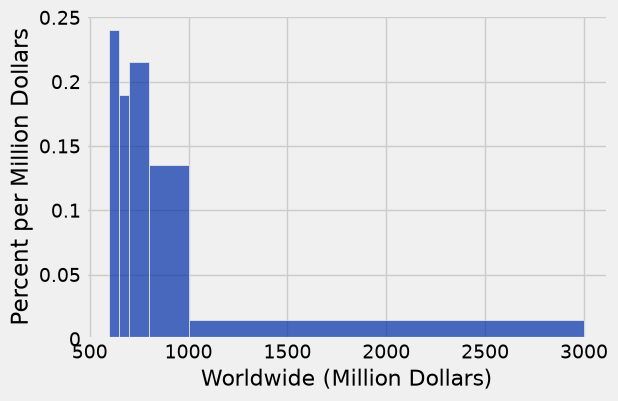

In [9]:
# datascience
uneven = make_array(600, 650, 700, 800, 1000, 3000)
top_movies = top_movies.with_column('Worldwide',
                       top_movies.column('Worldwide Lifetime Gross') / 1e6
                      )
top_movies.hist('Worldwide', bins=uneven, unit='Million Dollars')


In [10]:
# polars
# hvplot
uneven_pl = pl.Series('values', [600, 650, 700, 800, 1000, 3000])
top_movies_pl = top_movies_pl.with_columns((top_movies_pl.get_column('Worldwide Lifetime Gross') / 1e6).alias('Worldwide'))
top_movies_pl.hvplot.hist(y='Worldwide', normed=True, bins=(uneven_pl).to_list(), xlabel='Worldwide (Million Dollars)')


:Histogram   [Worldwide]   (Frequency)

In [11]:
# datascience
top_movies.bin('Worldwide', bins=uneven)


bin,Worldwide count
600,24
650,19
700,43
800,54
1000,60
3000,0


In [12]:
# polars
top_movies_pl.get_column('Worldwide').hist(bins=(uneven_pl).to_list()).rename({'breakpoint': 'bin', 'count': 'Worldwide count'}).drop('category')


bin,Worldwide count
f64,u32
650.0,24
700.0,19
800.0,43
1000.0,54
3000.0,60


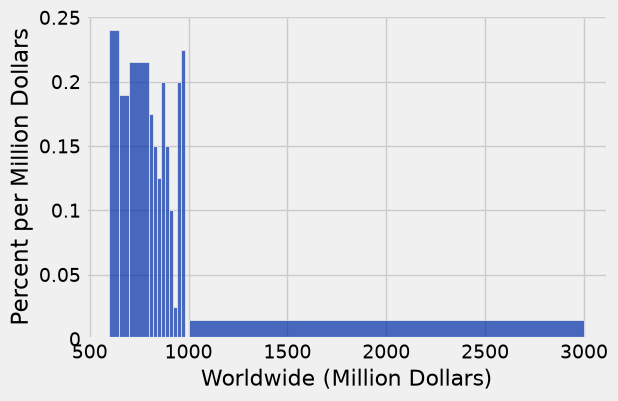

In [13]:
# datascience
some_tiny_bins = make_array(600, 650, 700, 800, 820, 840, 860, 880, 900, 920, 940, 960, 980, 1000, 3000)
top_movies.hist('Worldwide', bins=some_tiny_bins, unit='Million Dollars')


In [14]:
# polars
# hvplot
some_tiny_bins_pl = pl.Series('values', [600, 650, 700, 800, 820, 840, 860, 880, 900, 920, 940, 960, 980, 1000, 3000])
top_movies_pl.hvplot.hist(y='Worldwide', normed=True, bins=(some_tiny_bins_pl).to_list(), xlabel='Worldwide (Million Dollars)')


:Histogram   [Worldwide]   (Frequency)

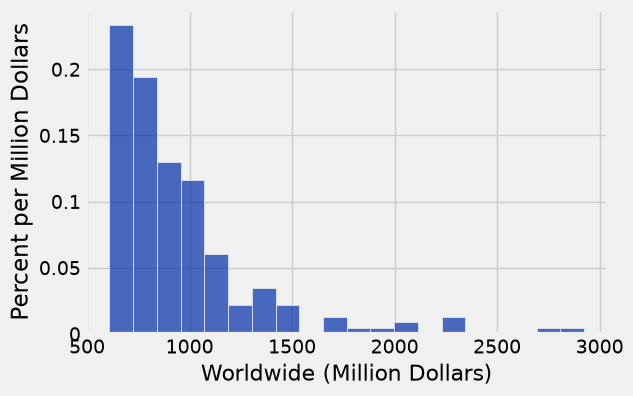

In [15]:
# datascience
top_movies.hist('Worldwide', bins=20, unit='Million Dollars')


In [16]:
# polars
# hvplot
top_movies_pl.hvplot.hist(y='Worldwide', normed=True, bins=20, xlabel='Worldwide (Million Dollars)')


:Histogram   [Worldwide]   (Frequency)

## Defining Functions ##  

Example: Create a function that takes a numerical input and triples it.

In [17]:
def triple(x):
    return 3 * x

In [18]:
triple(3)

9

In [19]:
triple(triple(3))

27

We can also assign a value to a name, and call the function on the name:

In [20]:
num = 4

In [21]:
triple(num)

12

In [22]:
triple(num * 5)

60

### Functions are Type-Agnostic

In [23]:
triple('ha')

'hahaha'

In [24]:
# datascience
np.arange(4)


array([0, 1, 2, 3])

In [25]:
# polars
pl.int_range(4, eager=True)


literal
i64
0
1
2
3


Feed the array above into our function `triple` to see what is produced:

In [26]:
# datascience
triple(np.arange(4))


array([0, 3, 6, 9])

In [27]:
# polars
triple(pl.int_range(4, eager=True))


literal
i64
0
3
6
9


---

### Discussion ###

- What does the following function do?
- What type of input does it take?
- What type of output does it produce?
- What's a good name for the function?

```python
def f(s):     
      return np.round(s / sum(s) * 100, 2)
```

<br/><br/><br/><br/><br/>
<br/><br/><br/><br/><br/>

In [28]:
# datascience
def percent_of_total(s):
    return np.round(s / sum(s) * 100, 2)


In [29]:
# polars
def percent_of_total_pl(s):
    return (s / sum(s) * 100).round(2)


In [30]:
# datascience
first_four=make_array(1,2,3,4)
first_four


array([1, 2, 3, 4])

In [31]:
# polars
first_four_pl=pl.Series('values', [1,2,3,4])
first_four_pl


values
i64
1
2
3
4


In [32]:
percent_of_total(first_four)

array([ 10.,  20.,  30.,  40.])

In [33]:
# datascience
percent_of_total(make_array(1, 213, 38))


array([  0.4 ,  84.52,  15.08])

In [34]:
# polars
percent_of_total_pl(pl.Series('values', [1, 213, 38]))


values
f64
0.4
84.52
15.08


---

## A strategy for defining functions:
- Give generic, descriptive names to some example inputs.
- Try writing the code that gives you the right output for that example.
- Once that works, put that code into a `def` statement (without the example; with a `return`).
- Try calling it on some different example inputs (to make sure it's flexible).

---

## Functions Can Take Multiple Arguments

### Example: Calculate the Hypotenuse Length of a Right Triangle


Pythagoras's Theorem: If $x$ and $y$ denote the lengths of the right-angle sides, then the hypotenuse length $h$ satisfies:

$$ h^2 = x^2 + y^2 \qquad \text{which implies}\qquad \hspace{20 pt} h = \sqrt{ x^2 + y^2 } $$

In [35]:
def hypotenuse(x, y):
    hypot_squared = (x ** 2 + y ** 2)
    hypot = hypot_squared ** 0.5
    return hypot

In [36]:
hypotenuse(1, 2)

2.23606797749979

In [37]:
hypotenuse(3, 4)

5.0

We could've typed the body all in one line. Do you find this more readable or less readable than the original version?

In [38]:
def hypotenuse(x,y):
    return (x ** 2 + y ** 2) ** 0.5

In [39]:
hypotenuse(9, 12)

15.0

### Example: A function that takes the year of birth of a person and produces their age in years. ###

In [40]:
def age(year):
    age = 2026 - year
    return age

In [41]:
age(1980)

46

Now add some bells and whistles:  Take person's name and year of birth (two arguments). Produce a sentence that states how old they are.

In [42]:
def name_and_age(name, year):
    return name + ' is ' + str(age(year)) + ' years old.'

In [43]:
name_and_age('Lisa', 1991)

'Lisa is 35 years old.'

---

## Apply

Characters from [_The Office_](https://en.wikipedia.org/wiki/The_Office_(American_TV_series))

In [44]:
# datascience
ages = Table().with_columns(
    'Person', make_array('Jim', 'Pam', 'Michael', 'Creed'),
    'Birth Year', make_array(1985, 1988, 1967, 1904)
)
ages


Person,Birth Year
Jim,1985
Pam,1988
Michael,1967
Creed,1904


In [45]:
# polars
ages_pl = pl.DataFrame([
    (pl.Series('values', ['Jim', 'Pam', 'Michael', 'Creed'])).alias('Person'),
    (pl.Series('values', [1985, 1988, 1967, 1904])).alias('Birth Year')
])
ages_pl


Person,Birth Year
str,i64
"""Jim""",1985
"""Pam""",1988
"""Michael""",1967
"""Creed""",1904


In [46]:
# datascience
ages.apply(age, 'Birth Year')


array([ 41,  38,  59, 122])

In [47]:
# polars
ages_pl.get_column('Birth Year').map_elements(age, return_dtype=pl.Int64)


Birth Year
i64
41
38
59
122


In [48]:
# datascience

make_array(age(ages.column('Birth Year').item(0)),
           age(ages.column('Birth Year').item(1)),
           age(ages.column('Birth Year').item(2)),
           age(ages.column('Birth Year').item(3)))


array([ 41,  38,  59, 122])

In [49]:
# polars

pl.Series('values', [age(ages_pl.get_column('Birth Year').item(0)),
           age(ages_pl.get_column('Birth Year').item(1)),
           age(ages_pl.get_column('Birth Year').item(2)),
           age(ages_pl.get_column('Birth Year').item(3))])


values
i64
41
38
59
122


In [50]:
# datascience
ages.apply(name_and_age, 'Person', 'Birth Year')


array(['Jim is 41 years old.', 'Pam is 38 years old.',
       'Michael is 59 years old.', 'Creed is 122 years old.'],
      dtype='<U24')

In [51]:
# polars
ages_pl.select(pl.struct(['Person', 'Birth Year']).map_elements(lambda row: name_and_age(row['Person'], row['Birth Year']), return_dtype=pl.String)).to_series()


Person
str
"""Jim is 41 years old."""
"""Pam is 38 years old."""
"""Michael is 59 years old."""
"""Creed is 122 years old."""
